In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Titanic ML environment is ready!")

Titanic ML environment is ready!


In [2]:
import kagglehub

kagglehub.login()

In [3]:
path = kagglehub.competition_download("titanic")

print("Dataset location:", path)

Dataset location: C:\Users\user\.cache\kagglehub\competitions\titanic


In [4]:
import pandas as pd
from pathlib import Path

train = pd.read_csv(Path(path) / "train.csv")
test = pd.read_csv(Path(path) / "test.csv")

train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [6]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [7]:
train.groupby("Sex")["Survived"].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [8]:
train.groupby("Pclass")["Survived"].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [9]:
train.groupby(["Sex", "Pclass"])["Survived"].mean()

Sex     Pclass
female  1         0.968085
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: Survived, dtype: float64

In [10]:
train["AgeGroup"] = pd.cut(
    train["Age"],
    bins=[0, 12, 18, 35, 60, float("inf")],
    labels=["Child", "Teen", "Young Adult", "Adult", "Senior"]
)

train.groupby("AgeGroup", observed=True)["Survived"].mean()

AgeGroup
Child          0.579710
Teen           0.428571
Young Adult    0.382682
Adult          0.400000
Senior         0.227273
Name: Survived, dtype: float64

In [11]:
train.groupby(["AgeGroup", "Pclass"], observed=True)["Survived"].mean()

AgeGroup     Pclass
Child        1         0.750000
             2         1.000000
             3         0.416667
Teen         1         0.916667
             2         0.500000
             3         0.282609
Young Adult  1         0.757576
             2         0.436170
             3         0.232323
Adult        1         0.611111
             2         0.382979
             3         0.086207
Senior       1         0.214286
             2         0.333333
             3         0.200000
Name: Survived, dtype: float64

In [12]:
train.groupby(
    ["AgeGroup", "Pclass"],
    observed=True
)["Survived"].mean().unstack()

Pclass,1,2,3
AgeGroup,,,
Child,0.750000,1.000000,0.416667
Teen,0.916667,0.500000,0.282609
Young Adult,0.757576,0.436170,0.232323
Adult,0.611111,0.382979,0.086207
Senior,0.214286,0.333333,0.200000


In [13]:
train.groupby(
    ["AgeGroup", "Pclass"],
    observed=True
)["Survived"].agg(["count", "sum", "mean"])

count  sum      mean
AgeGroup    Pclass                      
Child       1           4    3  0.750000
            2          17   17  1.000000
            3          48   20  0.416667
Teen        1          12   11  0.916667
            2          12    6  0.500000
            3          46   13  0.282609
Young Adult 1          66   50  0.757576
            2          94   41  0.436170
            3         198   46  0.232323
Adult       1          90   55  0.611111
            2          47   18  0.382979
            3          58    5  0.086207
Senior      1          14    3  0.214286
            2           3    1  0.333333
            3           5    1  0.200000

In [14]:
features = ["Sex", "Pclass", "Age"]

X = train[features]
y = train["Survived"]

In [15]:
from sklearn.model_selection import train_test_split

features = ["Sex", "Pclass", "Age"]

X = train[features]
y = train["Survived"]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training passengers:", X_train.shape[0])
print("Validation passengers:", X_val.shape[0])

Training passengers: 712
Validation passengers: 179


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("age", SimpleImputer(strategy="median"), ["Age"]),
        ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"]),
        ("class", "passthrough", ["Pclass"])
    ]
)

In [17]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('age', ...), ('sex', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [19]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['Sex','Pclass','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('age', ...), ('sex', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified

In [20]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_val)

accuracy = accuracy_score(y_val, y_pred)

print("Validation accuracy:", accuracy)

Validation accuracy: 0.7932960893854749


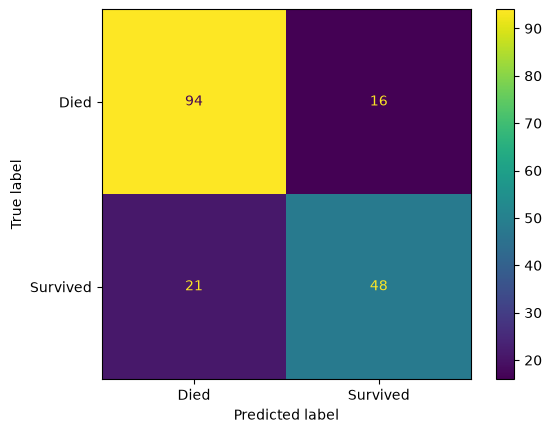

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_val, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Died", "Survived"]
).plot()

plt.show()

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ))
])

In [23]:
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['Sex','Pclass','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('age', ...), ('sex', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified

In [24]:
rf_pred = rf_model.predict(X_val)

rf_accuracy = accuracy_score(y_val, rf_pred)

print("Logistic Regression:", accuracy)
print("Random Forest:", rf_accuracy)

Logistic Regression: 0.7932960893854749
Random Forest: 0.7821229050279329


In [25]:
features_v2 = [
    "Sex",
    "Pclass",
    "Age",
    "Fare",
    "SibSp",
    "Parch",
    "Embarked"
]

X_v2 = train[features_v2]
y = train["Survived"]

In [26]:
X_train_v2, X_val_v2, y_train_v2, y_val_v2 = train_test_split(
    X_v2,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train_v2.shape)
print("Validation:", X_val_v2.shape)

Training: (712, 7)
Validation: (179, 7)


In [27]:
preprocessor_v2 = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            ["Age", "Fare", "SibSp", "Parch", "Pclass"]
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            ["Sex", "Embarked"]
        )
    ]
)

In [28]:
lr_model_v2 = Pipeline([
    ("preprocessing", preprocessor_v2),
    ("classifier", LogisticRegression(max_iter=1000))
])

lr_model_v2.fit(X_train_v2, y_train_v2)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['Sex','Pclass','Age',...,'SibSp','Parch','Embarked']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all re

In [29]:
lr_pred_v2 = lr_model_v2.predict(X_val_v2)

lr_accuracy_v2 = accuracy_score(y_val_v2, lr_pred_v2)

print("Logistic Regression V1:", accuracy)
print("Logistic Regression V2:", lr_accuracy_v2)

Logistic Regression V1: 0.7932960893854749
Logistic Regression V2: 0.8044692737430168


In [30]:
rf_model_v2 = Pipeline([
    ("preprocessing", preprocessor_v2),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ))
])

rf_model_v2.fit(X_train_v2, y_train_v2)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['Sex','Pclass','Age',...,'SibSp','Parch','Embarked']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all re

In [31]:
rf_pred_v2 = rf_model_v2.predict(X_val_v2)

rf_accuracy_v2 = accuracy_score(y_val_v2, rf_pred_v2)

results = pd.DataFrame({
    "Model": [
        "Logistic Regression V1",
        "Random Forest V1",
        "Logistic Regression V2",
        "Random Forest V2"
    ],
    "Accuracy": [
        accuracy,
        rf_accuracy,
        lr_accuracy_v2,
        rf_accuracy_v2
    ]
})

results.sort_values("Accuracy", ascending=False)

,Model,Accuracy
3,Random Forest V2,0.804469
2,Logistic Regression V2,0.804469
0,Logistic Regression V1,0.793296
1,Random Forest V1,0.782123


In [32]:
comparison = pd.DataFrame({
    "Actual": y_val_v2.values,
    "Logistic Regression": lr_pred_v2,
    "Random Forest": rf_pred_v2
})

comparison.head(10)

,Actual,Logistic Regression,Random Forest
0,0,0,0
1,0,0,0
2,1,0,0
3,0,0,0
4,1,1,1
5,1,0,0
6,1,1,1
7,0,0,0
8,0,0,0
9,0,0,0


In [33]:
print(
    "Different predictions:",
    (lr_pred_v2 != rf_pred_v2).sum()
)

Different predictions: 10


In [34]:
disagreements = comparison[
    comparison["Logistic Regression"] != comparison["Random Forest"]
]

disagreements

,Actual,Logistic Regression,Random Forest
51,0,1,0
54,1,1,0
65,0,1,0
79,0,1,0
87,1,1,0
88,0,1,0
142,1,1,0
160,1,1,0
169,1,1,0
172,0,1,0


In [35]:
from sklearn.base import clone

final_model = clone(rf_model_v2)

final_model.fit(X_v2, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['Sex','Pclass','Age',...,'SibSp','Parch','Embarked']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all re

In [36]:
X_test = test[features_v2]

test_predictions = final_model.predict(X_test)

print("Number of predictions:", len(test_predictions))

Number of predictions: 418


In [37]:
submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test_predictions
})

submission.to_csv("submission.csv", index=False)

submission.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


In [38]:
features_v3 = [
    "Age",
    "Sex",
    "Pclass",
    "SibSp",
    "Parch",
    "Fare"
]

X_v3 = train[features_v3]
y = train["Survived"]

In [39]:
X_train_v3, X_val_v3, y_train_v3, y_val_v3 = train_test_split(
    X_v3,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train_v3.shape)
print("Validation:", X_val_v3.shape)

Training: (712, 6)
Validation: (179, 6)


In [40]:
preprocessor_v3 = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            ["Age", "Pclass", "SibSp", "Parch", "Fare"]
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            ["Sex"]
        )
    ]
)

In [41]:
lr_model_v3 = Pipeline([
    ("preprocessing", preprocessor_v3),
    ("classifier", LogisticRegression(max_iter=1000))
])

lr_model_v3.fit(X_train_v3, y_train_v3)

lr_pred_v3 = lr_model_v3.predict(X_val_v3)

lr_accuracy_v3 = accuracy_score(y_val_v3, lr_pred_v3)

print("Logistic Regression V3:", lr_accuracy_v3)

Logistic Regression V3: 0.8100558659217877


In [42]:
rf_model_v3 = Pipeline([
    ("preprocessing", preprocessor_v3),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ))
])

rf_model_v3.fit(X_train_v3, y_train_v3)

rf_pred_v3 = rf_model_v3.predict(X_val_v3)

rf_accuracy_v3 = accuracy_score(y_val_v3, rf_pred_v3)

print("Random Forest V3:", rf_accuracy_v3)

Random Forest V3: 0.8044692737430168


In [43]:
results_v3 = pd.DataFrame({
    "Model": [
        "Logistic Regression V1",
        "Random Forest V1",
        "Logistic Regression V2",
        "Random Forest V2",
        "Logistic Regression V3",
        "Random Forest V3"
    ],
    "Accuracy": [
        accuracy,
        rf_accuracy,
        lr_accuracy_v2,
        rf_accuracy_v2,
        lr_accuracy_v3,
        rf_accuracy_v3
    ]
})

results_v3.sort_values("Accuracy", ascending=False)

,Model,Accuracy
4,Logistic Regression V3,0.810056
2,Logistic Regression V2,0.804469
3,Random Forest V2,0.804469
5,Random Forest V3,0.804469
0,Logistic Regression V1,0.793296
1,Random Forest V1,0.782123


In [44]:
from xgboost import XGBClassifier

xgb_model_v3 = Pipeline([
    ("preprocessing", preprocessor_v3),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42
    ))
])

In [45]:
xgb_model_v3.fit(X_train_v3, y_train_v3)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Age','Sex','Pclass','SibSp','Parch','Fare']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining 

In [46]:
xgb_pred_v3 = xgb_model_v3.predict(X_val_v3)

xgb_accuracy_v3 = accuracy_score(y_val_v3, xgb_pred_v3)

print("XGBoost V3 Accuracy:", xgb_accuracy_v3)

XGBoost V3 Accuracy: 0.776536312849162


In [47]:
results_v4 = pd.concat([
    results_v3,
    pd.DataFrame({
        "Model": ["XGBoost V3"],
        "Accuracy": [xgb_accuracy_v3]
    })
], ignore_index=True)

results_v4.sort_values("Accuracy", ascending=False)

,Model,Accuracy
4,Logistic Regression V3,0.810056
3,Random Forest V2,0.804469
2,Logistic Regression V2,0.804469
5,Random Forest V3,0.804469
0,Logistic Regression V1,0.793296
1,Random Forest V1,0.782123
6,XGBoost V3,0.776536


In [48]:
from sklearn.naive_bayes import GaussianNB

preprocessor_nb = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            ["Age", "Pclass", "SibSp", "Parch", "Fare"]
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            ["Sex"]
        )
    ]
)

nb_model_v3 = Pipeline([
    ("preprocessing", preprocessor_nb),
    ("classifier", GaussianNB())
])

In [49]:
nb_model_v3.fit(X_train_v3, y_train_v3)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Age','Sex','Pclass','SibSp','Parch','Fare']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining 

In [50]:
nb_pred_v3 = nb_model_v3.predict(X_val_v3)

nb_accuracy_v3 = accuracy_score(y_val_v3, nb_pred_v3)

print("Naive Bayes V3:", nb_accuracy_v3)

Naive Bayes V3: 0.7988826815642458


In [51]:
results_v5 = pd.concat([
    results_v4,
    pd.DataFrame({
        "Model": ["Naive Bayes V3"],
        "Accuracy": [nb_accuracy_v3]
    })
], ignore_index=True)

results_v5.sort_values("Accuracy", ascending=False)

,Model,Accuracy
4,Logistic Regression V3,0.810056
3,Random Forest V2,0.804469
5,Random Forest V3,0.804469
2,Logistic Regression V2,0.804469
7,Naive Bayes V3,0.798883
0,Logistic Regression V1,0.793296
1,Random Forest V1,0.782123
6,XGBoost V3,0.776536


In [52]:
for df in [train, test]:
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

    df["Title"] = df["Name"].str.extract(r",\s*([^.]*)\.")[0]

    df["Title"] = df["Title"].replace({
        "Mlle": "Miss",
        "Ms": "Miss",
        "Mme": "Mrs"
    })

    common_titles = ["Mr", "Mrs", "Miss", "Master"]

    df["Title"] = df["Title"].where(
        df["Title"].isin(common_titles),
        "Rare"
    )

In [53]:
features_v4 = [
    "Age",
    "Sex",
    "Pclass",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize",
    "IsAlone",
    "Title"
]

X_v4 = train[features_v4]
y = train["Survived"]

X_train_v4, X_val_v4, y_train_v4, y_val_v4 = train_test_split(
    X_v4,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train_v4.shape)
print("Validation:", X_val_v4.shape)

Training: (712, 9)
Validation: (179, 9)


In [54]:
preprocessor_v4 = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            [
                "Age", "Pclass", "SibSp",
                "Parch", "Fare", "FamilySize", "IsAlone"
            ]
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            ["Sex", "Title"]
        )
    ]
)

In [55]:
models_v4 = {
    "Logistic Regression V4": LogisticRegression(max_iter=1000),
    "Random Forest V4": RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ),
    "XGBoost V4": XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42
    ),
    "Naive Bayes V4": GaussianNB()
}

trained_models_v4 = {}
scores_v4 = {}

for name, classifier in models_v4.items():
    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor_v4)),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train_v4, y_train_v4)

    predictions = pipeline.predict(X_val_v4)

    scores_v4[name] = accuracy_score(y_val_v4, predictions)
    trained_models_v4[name] = pipeline

    print(f"{name}: {scores_v4[name]:.4f}")

Logistic Regression V4: 0.8380
Random Forest V4: 0.8324
XGBoost V4: 0.8045
Naive Bayes V4: 0.8212


In [56]:
results_v4_new = pd.DataFrame({
    "Model": list(scores_v4.keys()),
    "Accuracy": list(scores_v4.values())
})

all_results = pd.concat(
    [results_v5, results_v4_new],
    ignore_index=True
)

all_results.sort_values("Accuracy", ascending=False)

,Model,Accuracy
8,Logistic Regression V4,0.837989
9,Random Forest V4,0.832402
11,Naive Bayes V4,0.821229
4,Logistic Regression V3,0.810056
5,Random Forest V3,0.804469
10,XGBoost V4,0.804469
2,Logistic Regression V2,0.804469
3,Random Forest V2,0.804469
7,Naive Bayes V3,0.798883
0,Logistic Regression V1,0.793296


In [57]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.base import clone

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = {}

for name, model in trained_models_v4.items():
    scores = cross_val_score(
        clone(model),
        X_train_v4,
        y_train_v4,
        cv=cv,
        scoring="accuracy"
    )

    cv_results[name] = scores.mean()

    print(f"{name}: {scores.mean():.4f} ± {scores.std():.4f}")

Logistic Regression V4: 0.8188 ± 0.0200
Random Forest V4: 0.8301 ± 0.0148
XGBoost V4: 0.8343 ± 0.0306
Naive Bayes V4: 0.8034 ± 0.0199


In [58]:
for df in [train, test]:
    df["Sex_Pclass"] = (
        df["Sex"] + "_" + df["Pclass"].astype(str)
    )

train[["Sex", "Pclass", "Sex_Pclass", "Survived"]].head(10)

,Sex,Pclass,Sex_Pclass,Survived
0,male,3,male_3,0
1,female,1,female_1,1
2,female,3,female_3,1
3,female,1,female_1,1
4,male,3,male_3,0
5,male,3,male_3,0
6,male,1,male_1,0
7,male,3,male_3,0
8,female,3,female_3,1
9,female,2,female_2,1


In [59]:
features_v5 = features_v4 + ["Sex_Pclass"]

X_v5 = train[features_v5]
y = train["Survived"]

X_train_v5, X_val_v5, y_train_v5, y_val_v5 = train_test_split(
    X_v5,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train_v5.shape)
print("Validation:", X_val_v5.shape)

Training: (712, 10)
Validation: (179, 10)


In [60]:
preprocessor_v5 = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            [
                "Age", "Pclass", "SibSp",
                "Parch", "Fare", "FamilySize", "IsAlone"
            ]
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            ["Sex", "Title", "Sex_Pclass"]
        )
    ]
)

In [61]:
trained_models_v5 = {}
scores_v5 = {}

for name, classifier in models_v4.items():
    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor_v5)),
        ("classifier", clone(classifier))
    ])

    pipeline.fit(X_train_v5, y_train_v5)

    predictions = pipeline.predict(X_val_v5)

    model_name = name.replace("V4", "V5")

    scores_v5[model_name] = accuracy_score(y_val_v5, predictions)
    trained_models_v5[model_name] = pipeline

    print(f"{model_name}: {scores_v5[model_name]:.4f}")

Logistic Regression V5: 0.8547
Random Forest V5: 0.8380
XGBoost V5: 0.8101
Naive Bayes V5: 0.7989


In [62]:
comparison_v5 = pd.DataFrame({
    "Model": list(models_v4.keys()),
    "V4 Accuracy": [
        scores_v4[name] for name in models_v4
    ],
    "V5 Accuracy": [
        scores_v5[name.replace("V4", "V5")] for name in models_v4
    ]
})

comparison_v5["Improvement"] = (
    comparison_v5["V5 Accuracy"] - comparison_v5["V4 Accuracy"]
)

comparison_v5

,Model,V4 Accuracy,V5 Accuracy,Improvement
0,Logistic Regression V4,0.837989,0.854749,0.016760
1,Random Forest V4,0.832402,0.837989,0.005587
2,XGBoost V4,0.804469,0.810056,0.005587
3,Naive Bayes V4,0.821229,0.798883,-0.022346


In [63]:
cv_results_v5 = {}

for name, model in trained_models_v5.items():
    scores = cross_val_score(
        clone(model),
        X_train_v5,
        y_train_v5,
        cv=cv,
        scoring="accuracy"
    )

    cv_results_v5[name] = scores.mean()

    print(f"{name}: {scores.mean():.4f} ± {scores.std():.4f}")

Logistic Regression V5: 0.8188 ± 0.0241
Random Forest V5: 0.8188 ± 0.0155
XGBoost V5: 0.8259 ± 0.0305
Naive Bayes V5: 0.7950 ± 0.0222


In [64]:
for df in [train, test]:
    df["FamilyCategory"] = pd.cut(
        df["FamilySize"],
        bins=[0, 1, 4, float("inf")],
        labels=["Alone", "Small", "Large"]
    )

train.groupby("FamilyCategory", observed=True)["Survived"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
FamilyCategory,,,
Alone,537,163,0.303538
Small,292,169,0.578767
Large,62,10,0.161290


In [65]:
features_v6 = features_v4 + ["FamilyCategory"]

X_v6 = train[features_v6]
y = train["Survived"]

X_train_v6, X_val_v6, y_train_v6, y_val_v6 = train_test_split(
    X_v6,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train_v6.shape)
print("Validation:", X_val_v6.shape)

Training: (712, 10)
Validation: (179, 10)


In [66]:
preprocessor_v6 = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            [
                "Age", "Pclass", "SibSp",
                "Parch", "Fare", "FamilySize", "IsAlone"
            ]
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            ["Sex", "Title", "FamilyCategory"]
        )
    ]
)

In [67]:
cv_results_v6 = {}

for name, classifier in models_v4.items():
    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor_v6)),
        ("classifier", clone(classifier))
    ])

    scores = cross_val_score(
        pipeline,
        X_train_v6,
        y_train_v6,
        cv=cv,
        scoring="accuracy"
    )

    model_name = name.replace("V4", "V6")
    cv_results_v6[model_name] = scores.mean()

    print(f"{model_name}: {scores.mean():.4f} ± {scores.std():.4f}")

Logistic Regression V6: 0.8230 ± 0.0232
Random Forest V6: 0.8258 ± 0.0102
XGBoost V6: 0.8217 ± 0.0317
Naive Bayes V6: 0.8244 ± 0.0214


In [68]:
comparison_v6 = pd.DataFrame({
    "Model": list(models_v4.keys()),
    "V4 CV Accuracy": [
        cv_results[name] for name in models_v4
    ],
    "V6 CV Accuracy": [
        cv_results_v6[name.replace("V4", "V6")]
        for name in models_v4
    ]
})

comparison_v6["Improvement"] = (
    comparison_v6["V6 CV Accuracy"]
    - comparison_v6["V4 CV Accuracy"]
)

comparison_v6

,Model,V4 CV Accuracy,V6 CV Accuracy,Improvement
0,Logistic Regression V4,0.818832,0.823047,0.004216
1,Random Forest V4,0.830070,0.825845,-0.004225
2,XGBoost V4,0.834335,0.821678,-0.012656
3,Naive Bayes V4,0.803368,0.824426,0.021058


In [69]:
for df in [train, test]:
    df["HasCabin"] = df["Cabin"].notna().astype(int)

train.groupby("HasCabin")["Survived"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
HasCabin,,,
0,687,206,0.299854
1,204,136,0.666667


In [70]:
train.groupby(["Pclass", "HasCabin"])["Survived"].agg(
    ["count", "mean"]
)

count      mean
Pclass HasCabin                 
1      0            40  0.475000
       1           176  0.664773
2      0           168  0.440476
       1            16  0.812500
3      0           479  0.235908
       1            12  0.500000

In [71]:
features_v7 = features_v4 + ["HasCabin"]

X_v7 = train[features_v7]
y = train["Survived"]

X_train_v7, X_val_v7, y_train_v7, y_val_v7 = train_test_split(
    X_v7,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train_v7.shape)
print("Validation:", X_val_v7.shape)

Training: (712, 10)
Validation: (179, 10)


In [72]:
preprocessor_v7 = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            [
                "Age", "Pclass", "SibSp", "Parch",
                "Fare", "FamilySize", "IsAlone", "HasCabin"
            ]
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            ["Sex", "Title"]
        )
    ]
)

In [73]:
cv_results_v7 = {}

for name, classifier in models_v4.items():
    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor_v7)),
        ("classifier", clone(classifier))
    ])

    scores = cross_val_score(
        pipeline,
        X_train_v7,
        y_train_v7,
        cv=cv,
        scoring="accuracy"
    )

    model_name = name.replace("V4", "V7")
    cv_results_v7[model_name] = scores.mean()

    print(f"{model_name}: {scores.mean():.4f} ± {scores.std():.4f}")

Logistic Regression V7: 0.8231 ± 0.0259
Random Forest V7: 0.8273 ± 0.0218
XGBoost V7: 0.8329 ± 0.0325
Naive Bayes V7: 0.8118 ± 0.0152


In [74]:
for df in [train, test]:
    df["Deck"] = df["Cabin"].str[0].fillna("Unknown")

train[["Cabin", "Deck", "Pclass", "Survived"]].head(10)

,Cabin,Deck,Pclass,Survived
0,NaN,Unknown,3,0
1,C85,C,1,1
2,NaN,Unknown,3,1
3,C123,C,1,1
4,NaN,Unknown,3,0
5,NaN,Unknown,3,0
6,E46,E,1,0
7,NaN,Unknown,3,0
8,NaN,Unknown,3,1
9,NaN,Unknown,2,1


In [75]:
train.groupby("Deck")["Survived"].agg(
    ["count", "sum", "mean"]
).sort_values("mean", ascending=False)

,count,sum,mean
Deck,,,
D,33,25,0.757576
E,32,24,0.750000
B,47,35,0.744681
F,13,8,0.615385
C,59,35,0.593220
G,4,2,0.500000
A,15,7,0.466667
Unknown,687,206,0.299854
T,1,0,0.000000


In [76]:
features_v8 = features_v4 + ["Deck"]

X_v8 = train[features_v8]
y = train["Survived"]

X_train_v8, X_val_v8, y_train_v8, y_val_v8 = train_test_split(
    X_v8,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train_v8.shape)
print("Validation:", X_val_v8.shape)

Training: (712, 10)
Validation: (179, 10)


In [77]:
preprocessor_v8 = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            [
                "Age", "Pclass", "SibSp", "Parch",
                "Fare", "FamilySize", "IsAlone"
            ]
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            ["Sex", "Title", "Deck"]
        )
    ]
)

In [78]:
cv_results_v8 = {}

for name, classifier in models_v4.items():
    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor_v8)),
        ("classifier", clone(classifier))
    ])

    scores = cross_val_score(
        pipeline,
        X_train_v8,
        y_train_v8,
        cv=cv,
        scoring="accuracy"
    )

    model_name = name.replace("V4", "V8")
    cv_results_v8[model_name] = scores.mean()

    print(f"{model_name}: {scores.mean():.4f} ± {scores.std():.4f}")

Logistic Regression V8: 0.8189 ± 0.0351
Random Forest V8: 0.8259 ± 0.0198
XGBoost V8: 0.8259 ± 0.0310
Naive Bayes V8: 0.7978 ± 0.0444


In [79]:
comparison_v8 = pd.DataFrame({
    "Model": list(models_v4.keys()),
    "V4 CV Accuracy": [
        cv_results[name] for name in models_v4
    ],
    "V8 CV Accuracy": [
        cv_results_v8[name.replace("V4", "V8")]
        for name in models_v4
    ]
})

comparison_v8["Improvement"] = (
    comparison_v8["V8 CV Accuracy"]
    - comparison_v8["V4 CV Accuracy"]
)

comparison_v8

,Model,V4 CV Accuracy,V8 CV Accuracy,Improvement
0,Logistic Regression V4,0.818832,0.818871,0.000039
1,Random Forest V4,0.830070,0.825864,-0.004206
2,XGBoost V4,0.834335,0.825894,-0.008441
3,Naive Bayes V4,0.803368,0.797843,-0.005525


In [80]:
ticket_counts = train["Ticket"].value_counts()

ticket_counts.head(10)

Ticket
347082          7
1601            7
CA. 2343        7
3101295         6
CA 2144         6
347088          6
382652          5
S.O.C. 14879    5
349909          4
347077          4
Name: count, dtype: int64

In [81]:
print("Unique tickets:", train["Ticket"].nunique())
print("Tickets shared by multiple passengers:", (ticket_counts > 1).sum())

Unique tickets: 681
Tickets shared by multiple passengers: 134


In [82]:
from sklearn.base import BaseEstimator, TransformerMixin

class TicketGroupTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.ticket_counts_ = X["Ticket"].value_counts()
        return self

    def transform(self, X):
        X = X.copy()

        X["TicketGroupSize"] = (
            X["Ticket"]
            .map(self.ticket_counts_)
            .fillna(1)
            .astype(int)
        )

        return X.drop(columns=["Ticket"])

In [83]:
features_v9 = features_v4 + ["Ticket"]

X_v9 = train[features_v9]
y = train["Survived"]

X_train_v9, X_val_v9, y_train_v9, y_val_v9 = train_test_split(
    X_v9,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train_v9.shape)
print("Validation:", X_val_v9.shape)

Training: (712, 10)
Validation: (179, 10)


In [84]:
preprocessor_v9 = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            [
                "Age", "Pclass", "SibSp", "Parch",
                "Fare", "FamilySize", "IsAlone",
                "TicketGroupSize"
            ]
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            ["Sex", "Title"]
        )
    ]
)

In [85]:
cv_results_v9 = {}

for name, classifier in models_v4.items():
    pipeline = Pipeline([
        ("ticket_group", TicketGroupTransformer()),
        ("preprocessing", clone(preprocessor_v9)),
        ("classifier", clone(classifier))
    ])

    scores = cross_val_score(
        pipeline,
        X_train_v9,
        y_train_v9,
        cv=cv,
        scoring="accuracy"
    )

    model_name = name.replace("V4", "V9")
    cv_results_v9[model_name] = scores.mean()

    print(f"{model_name}: {scores.mean():.4f} ± {scores.std():.4f}")

Logistic Regression V9: 0.8188 ± 0.0173
Random Forest V9: 0.8315 ± 0.0237
XGBoost V9: 0.8329 ± 0.0311
Naive Bayes V9: 0.8034 ± 0.0236


In [86]:
comparison_v9 = pd.DataFrame({
    "Model": list(models_v4.keys()),
    "V4 CV Accuracy": [
        cv_results[name] for name in models_v4
    ],
    "V9 CV Accuracy": [
        cv_results_v9[name.replace("V4", "V9")]
        for name in models_v4
    ]
})

comparison_v9["Improvement"] = (
    comparison_v9["V9 CV Accuracy"]
    - comparison_v9["V4 CV Accuracy"]
)

comparison_v9

,Model,V4 CV Accuracy,V9 CV Accuracy,Improvement
0,Logistic Regression V4,0.818832,0.818832,2.220446e-16
1,Random Forest V4,0.830070,0.831488,1.418300e-03
2,XGBoost V4,0.834335,0.832897,-1.437999e-03
3,Naive Bayes V4,0.803368,0.803368,0.000000e+00


In [87]:
from sklearn.model_selection import RandomizedSearchCV

xgb_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor_v4)),
    ("classifier", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42
    ))
])

param_distributions = {
    "classifier__n_estimators": [100, 200, 300, 400],
    "classifier__max_depth": [2, 3, 4, 5],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__min_child_weight": [1, 3, 5]
}

random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="accuracy",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_v4, y_train_v4)

print("Best CV accuracy:", random_search.best_score_)
print("Best parameters:", random_search.best_params_)

Best CV accuracy: 0.8399487836107555
Best parameters: {'classifier__subsample': 0.9, 'classifier__n_estimators': 400, 'classifier__min_child_weight': 5, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.05, 'classifier__colsample_bytree': 0.8}


In [88]:
best_xgb = random_search.best_estimator_

In [89]:
best_xgb_pred = best_xgb.predict(X_val_v4)

best_xgb_accuracy = accuracy_score(
    y_val_v4,
    best_xgb_pred
)

print("Tuned XGBoost validation accuracy:", best_xgb_accuracy)

Tuned XGBoost validation accuracy: 0.8100558659217877


In [90]:
print("Original XGBoost V4:", scores_v4["XGBoost V4"])
print("Tuned XGBoost V4:", best_xgb_accuracy)
print("Logistic Regression V5:", scores_v5["Logistic Regression V5"])

Original XGBoost V4: 0.8044692737430168
Tuned XGBoost V4: 0.8100558659217877
Logistic Regression V5: 0.8547486033519553


In [91]:
from sklearn.base import clone

final_lr_v5 = clone(
    trained_models_v5["Logistic Regression V5"]
)

final_lr_v5.fit(X_v5, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Age','Sex','Pclass',...,'IsAlone','Title','Sex_Pclass']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, 

In [92]:
X_test_v5 = test[features_v5]

predictions_v5 = final_lr_v5.predict(X_test_v5)

print("Predictions:", len(predictions_v5))

Predictions: 418


In [93]:
submission_v5 = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": predictions_v5
})

submission_v5.to_csv(
    "submission_lr_v5.csv",
    index=False
)

submission_v5.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


In [94]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

rf_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor_v4)),
    ("classifier", RandomForestClassifier(random_state=42))
])

In [95]:
rf_param_distributions = {
    "classifier__n_estimators": [100, 200, 300, 500],
    "classifier__max_depth": [3, 5, 7, 10, None],
    "classifier__min_samples_split": [2, 5, 10, 15],
    "classifier__min_samples_leaf": [1, 2, 4, 6],
    "classifier__max_features": ["sqrt", "log2", 0.5, None],
    "classifier__bootstrap": [True, False]
}

In [96]:
rf_random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=40,
    scoring="accuracy",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

rf_random_search.fit(X_train_v4, y_train_v4)

print("Best CV accuracy:", rf_random_search.best_score_)
print("Best parameters:", rf_random_search.best_params_)

Best CV accuracy: 0.8441248891953117
Best parameters: {'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 0.5, 'classifier__max_depth': 10, 'classifier__bootstrap': False}


In [97]:
print("Original RF V4 CV:", cv_results["Random Forest V4"])
print("Tuned RF V4 CV:", rf_random_search.best_score_)

Original RF V4 CV: 0.8300699300699301
Tuned RF V4 CV: 0.8441248891953117


In [98]:
best_rf = rf_random_search.best_estimator_

best_rf_pred = best_rf.predict(X_val_v4)

best_rf_accuracy = accuracy_score(y_val_v4, best_rf_pred)

print("Original RF V4:", scores_v4["Random Forest V4"])
print("Tuned RF V4:", best_rf_accuracy)

Original RF V4: 0.8324022346368715
Tuned RF V4: 0.8100558659217877


In [99]:
final_rf_tuned = clone(rf_random_search.best_estimator_)

final_rf_tuned.fit(X_v4, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Age','Sex','Pclass',...,'FamilySize','IsAlone','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, al

In [100]:
X_test_v4 = test[features_v4]

rf_tuned_predictions = final_rf_tuned.predict(X_test_v4)

print("Predictions:", len(rf_tuned_predictions))

Predictions: 418


In [101]:
submission_rf_tuned = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": rf_tuned_predictions
})

submission_rf_tuned.to_csv(
    "submission_rf_tuned_v4.csv",
    index=False
)

submission_rf_tuned.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0


In [102]:

import pandas as pd
import numpy as np
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

# 1. Define features
numeric_features = [
    "Age", "Pclass", "SibSp", "Parch",
    "Fare", "FamilySize", "IsAlone"
]

categorical_features = ["Sex", "Title"]

# 2. Create 5-fold cross-validation
cv_cat = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cat_cv_scores = []

# 3. Train and evaluate CatBoost on each fold
for fold, (train_idx, val_idx) in enumerate(
    cv_cat.split(X_train_v4, y_train_v4), start=1
):
    X_tr = X_train_v4.iloc[train_idx].copy()
    X_vl = X_train_v4.iloc[val_idx].copy()

    y_tr = y_train_v4.iloc[train_idx]
    y_vl = y_train_v4.iloc[val_idx]

    # Fill missing numerical values using training-fold medians
    medians = X_tr[numeric_features].median()

    X_tr[numeric_features] = X_tr[numeric_features].fillna(medians)
    X_vl[numeric_features] = X_vl[numeric_features].fillna(medians)

    # Fill missing categorical values
    for col in categorical_features:
        X_tr[col] = X_tr[col].fillna("Unknown").astype(str)
        X_vl[col] = X_vl[col].fillna("Unknown").astype(str)

    # Create a fresh CatBoost model
    model = CatBoostClassifier(
        iterations=500,
        depth=4,
        learning_rate=0.03,
        loss_function="Logloss",
        verbose=False,
        random_seed=42,
        allow_writing_files=False
    )

    # Train with native categorical features
    model.fit(
        X_tr,
        y_tr,
        cat_features=categorical_features
    )

    predictions = model.predict(X_vl).ravel()

    score = accuracy_score(y_vl, predictions)
    cat_cv_scores.append(score)

    print(f"Fold {fold}: {score:.4f}")

# 4. Calculate average cross-validation accuracy
cat_mean = np.mean(cat_cv_scores)
cat_std = np.std(cat_cv_scores)

print(f"\nCatBoost V4 CV: {cat_mean:.4f} ± {cat_std:.4f}")

# 5. Compare with previous models
comparison_catboost = pd.DataFrame({
    "Model": [
        "Tuned Random Forest V4",
        "Tuned XGBoost V4",
        "CatBoost V4",
        "Original XGBoost V4",
        "Original Random Forest V4"
    ],
    "CV Accuracy": [
        rf_random_search.best_score_,
        random_search.best_score_,
        cat_mean,
        cv_results["XGBoost V4"],
        cv_results["Random Forest V4"]
    ]
})

comparison_catboost.sort_values(
    "CV Accuracy",
    ascending=False
)


Fold 1: 0.8322
Fold 2: 0.8042
Fold 3: 0.8592
Fold 4: 0.7887
Fold 5: 0.8380

CatBoost V4 CV: 0.8245 ± 0.0250


,Model,CV Accuracy
0,Tuned Random Forest V4,0.844125
1,Tuned XGBoost V4,0.839949
3,Original XGBoost V4,0.834335
4,Original Random Forest V4,0.830070
2,CatBoost V4,0.824456


In [103]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.base import clone

repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

models_to_compare = {
    "Random Forest V2": rf_model_v2,
    "Random Forest V4": trained_models_v4["Random Forest V4"],
    "Tuned Random Forest V4": rf_random_search.best_estimator_,
    "Original XGBoost V4": trained_models_v4["XGBoost V4"],
    "Tuned XGBoost V4": random_search.best_estimator_,
    "Logistic Regression V5": trained_models_v5["Logistic Regression V5"]
}

features_by_model = {
    "Random Forest V2": X_train_v2,
    "Random Forest V4": X_train_v4,
    "Tuned Random Forest V4": X_train_v4,
    "Original XGBoost V4": X_train_v4,
    "Tuned XGBoost V4": X_train_v4,
    "Logistic Regression V5": X_train_v5
}

repeated_results = {}

for name, model in models_to_compare.items():
    scores = cross_val_score(
        clone(model),
        features_by_model[name],
        y_train_v4,
        cv=repeated_cv,
        scoring="accuracy",
        n_jobs=-1
    )

    repeated_results[name] = scores.mean()

    print(f"{name}: {scores.mean():.4f} ± {scores.std():.4f}")

Random Forest V2: 0.8171 ± 0.0288
Random Forest V4: 0.8289 ± 0.0274
Tuned Random Forest V4: 0.8402 ± 0.0278
Original XGBoost V4: 0.8315 ± 0.0348
Tuned XGBoost V4: 0.8346 ± 0.0271
Logistic Regression V5: 0.8188 ± 0.0310


In [104]:
from sklearn.inspection import permutation_importance
import pandas as pd

importance = permutation_importance(
    best_rf,
    X_val_v4,
    y_val_v4,
    n_repeats=20,
    random_state=42,
    scoring="accuracy"
)

feature_importance = pd.DataFrame({
    "Feature": X_val_v4.columns,
    "Importance": importance.importances_mean
})

feature_importance.sort_values(
    "Importance",
    ascending=False
)

,Feature,Importance
8,Title,0.158659
1,Sex,0.065363
6,FamilySize,0.043855
2,Pclass,0.038827
0,Age,0.018436
5,Fare,0.004190
7,IsAlone,-0.000279
4,Parch,-0.002514
3,SibSp,-0.021508


In [105]:
features_v10 = [
    "Title", "Sex", "FamilySize",
    "Pclass", "Age", "Fare"
]

In [106]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.base import clone

# Select the six features
features_v10 = [
    "Title", "Sex", "FamilySize",
    "Pclass", "Age", "Fare"
]

X_v10 = train[features_v10]
y = train["Survived"]

# Use the same split as previous versions
X_train_v10, X_val_v10, y_train_v10, y_val_v10 = train_test_split(
    X_v10,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Preprocess numerical and categorical columns
preprocessor_v10 = ColumnTransformer([
    (
        "numeric",
        SimpleImputer(strategy="median"),
        ["FamilySize", "Pclass", "Age", "Fare"]
    ),
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        ["Title", "Sex"]
    )
])

# Reuse our tuned Random Forest settings
rf_v10 = Pipeline([
    ("preprocessing", preprocessor_v10),
    ("classifier", clone(
        rf_random_search.best_estimator_.named_steps["classifier"]
    ))
])

# Evaluate across 25 folds
scores_v10 = cross_val_score(
    rf_v10,
    X_train_v10,
    y_train_v10,
    cv=repeated_cv,
    scoring="accuracy",
    n_jobs=-1
)

print(f"Random Forest V10: {scores_v10.mean():.4f} ± {scores_v10.std():.4f}")
print(f"Random Forest V4: {repeated_results['Tuned Random Forest V4']:.4f}")

Random Forest V10: 0.8377 ± 0.0281
Random Forest V4: 0.8402


In [107]:
# Create a fresh copy of V10
final_rf_v10 = clone(rf_v10)

# Train on all 891 labeled passengers
final_rf_v10.fit(X_v10, y)

# Select the same features from Kaggle's test data
X_test_v10 = test[features_v10]

# Predict survival for 418 passengers
predictions_v10 = final_rf_v10.predict(X_test_v10)

# Create the submission file
submission_v10 = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": predictions_v10
})

submission_v10.to_csv(
    "submission_rf_v10.csv",
    index=False
)

print("Submission shape:", submission_v10.shape)
submission_v10.head()

Submission shape: (418, 2)


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


In [108]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Original V2 features
features_v2 = [
    "Sex", "Pclass", "Age", "Fare",
    "SibSp", "Parch", "Embarked"
]

X_v2 = train[features_v2]
y = train["Survived"]

# Use our original training and validation split
X_train_v2, X_val_v2, y_train_v2, y_val_v2 = train_test_split(
    X_v2,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Build the original V2 preprocessing pipeline
rf_v2_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor_v2)),
    ("classifier", RandomForestClassifier(random_state=42))
])

# Hyperparameter combinations
rf_v2_params = {
    "classifier__n_estimators": [100, 200, 300, 500, 700],
    "classifier__max_depth": [3, 4, 5, 6, 7, 8, 10, None],
    "classifier__min_samples_split": [2, 4, 6, 10, 15],
    "classifier__min_samples_leaf": [1, 2, 3, 4, 6],
    "classifier__max_features": ["sqrt", "log2", 0.5, 0.75, None],
    "classifier__bootstrap": [True, False]
}

# Randomized hyperparameter search
rf_v2_search = RandomizedSearchCV(
    estimator=rf_v2_pipeline,
    param_distributions=rf_v2_params,
    n_iter=60,
    scoring="accuracy",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True
)

rf_v2_search.fit(X_train_v2, y_train_v2)

print("Best RF V2 CV accuracy:", rf_v2_search.best_score_)
print("Best parameters:", rf_v2_search.best_params_)

Best RF V2 CV accuracy: 0.8244558258642766
Best parameters: {'classifier__n_estimators': 500, 'classifier__min_samples_split': 6, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 10, 'classifier__bootstrap': False}


In [109]:
original_v2_scores = cross_val_score(
    clone(rf_model_v2),
    X_train_v2,
    y_train_v2,
    cv=repeated_cv,
    scoring="accuracy",
    n_jobs=-1
)

tuned_v2_scores = cross_val_score(
    clone(rf_v2_search.best_estimator_),
    X_train_v2,
    y_train_v2,
    cv=repeated_cv,
    scoring="accuracy",
    n_jobs=-1
)

print(
    f"Original RF V2: "
    f"{original_v2_scores.mean():.4f} ± {original_v2_scores.std():.4f}"
)

print(
    f"Tuned RF V2: "
    f"{tuned_v2_scores.mean():.4f} ± {tuned_v2_scores.std():.4f}"
)

Original RF V2: 0.8171 ± 0.0288
Tuned RF V2: 0.8259 ± 0.0301


In [110]:
from sklearn.base import clone
import pandas as pd

# Create a fresh copy of the tuned Random Forest V2
final_rf_v2_tuned = clone(rf_v2_search.best_estimator_)

# Train using all 891 labeled passengers
final_rf_v2_tuned.fit(X_v2, y)

# Select the same seven features from Kaggle test data
X_test_v2 = test[features_v2]

# Predict survival for 418 passengers
predictions_rf_v2_tuned = final_rf_v2_tuned.predict(X_test_v2)

# Create the submission DataFrame
submission_rf_v2_tuned = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": predictions_rf_v2_tuned
})

# Save the CSV file
submission_rf_v2_tuned.to_csv(
    "submission_rf_v2_tuned.csv",
    index=False
)

# Verify submission format
print("Submission shape:", submission_rf_v2_tuned.shape)
print("Missing values:", submission_rf_v2_tuned.isnull().sum().sum())

submission_rf_v2_tuned.head()

Submission shape: (418, 2)
Missing values: 0


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


In [111]:
from sklearn.base import BaseEstimator, TransformerMixin

class AdjustedFareTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.ticket_counts_ = X["Ticket"].value_counts()
        return self

    def transform(self, X):
        X = X.copy()

        ticket_frequency = (
            X["Ticket"]
            .map(self.ticket_counts_)
            .fillna(1)
            .clip(lower=1)
        )

        X["AdjustedFare"] = X["Fare"] / ticket_frequency

        return X.drop(columns=["Ticket"])

In [112]:
features_v11 = features_v2 + ["Ticket"]

X_v11 = train[features_v11]
y = train["Survived"]

X_train_v11, X_val_v11, y_train_v11, y_val_v11 = train_test_split(
    X_v11,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train_v11.shape)
print("Validation:", X_val_v11.shape)

Training: (712, 8)
Validation: (179, 8)


In [113]:
preprocessor_v11 = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            [
                "Age", "Pclass", "Fare",
                "SibSp", "Parch", "AdjustedFare"
            ]
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            ["Sex", "Embarked"]
        )
    ]
)

In [114]:
rf_v11 = Pipeline([
    ("adjusted_fare", AdjustedFareTransformer()),
    ("preprocessing", preprocessor_v11),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ))
])

In [115]:
scores_v11 = cross_val_score(
    rf_v11,
    X_train_v11,
    y_train_v11,
    cv=repeated_cv,
    scoring="accuracy",
    n_jobs=-1
)

print(
    f"Random Forest V2: "
    f"{original_v2_scores.mean():.4f} ± {original_v2_scores.std():.4f}"
)

print(
    f"Random Forest V11: "
    f"{scores_v11.mean():.4f} ± {scores_v11.std():.4f}"
)

Random Forest V2: 0.8171 ± 0.0288
Random Forest V11: 0.8197 ± 0.0303


In [116]:
adult_males = train[
    (train["Sex"] == "male") &
    (train["Age"] >= 18)
]

print("Adult males:", len(adult_males))
print("Survival rate:", adult_males["Survived"].mean())

Adult males: 395
Survival rate: 0.17721518987341772


In [117]:
adult_males.groupby("Pclass")["Survived"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
Pclass,,,
1,97,36,0.371134
2,88,6,0.068182
3,210,28,0.133333


In [118]:
first_class_males = adult_males[
    adult_males["Pclass"] == 1
].copy()

first_class_males["AgeRange"] = pd.cut(
    first_class_males["Age"],
    bins=[17, 25, 35, 45, 60, float("inf")],
    labels=["18-25", "26-35", "36-45", "46-60", "60+"]
)

first_class_males.groupby(
    "AgeRange",
    observed=True
)["Survived"].agg(["count", "sum", "mean"])

,count,sum,mean
AgeRange,,,
18-25,10,3,0.300000
26-35,21,12,0.571429
36-45,24,10,0.416667
46-60,30,10,0.333333
60+,12,1,0.083333


In [119]:
young_first_class_males = first_class_males[
    (first_class_males["Age"] >= 26) &
    (first_class_males["Age"] <= 35)
]

young_first_class_males.groupby("FamilySize")["Survived"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
FamilySize,,,
1,15,10,0.666667
2,5,2,0.400000
3,1,0,0.000000


In [120]:
for df in [train, test]:
    df["YoungFirstClassSoloMale"] = (
        (df["Sex"] == "male") &
        (df["Pclass"] == 1) &
        (df["Age"].between(26, 35)) &
        (df["SibSp"] == 0) &
        (df["Parch"] == 0)
    ).astype(int)

In [121]:
group = X_val_v2.copy()

group["Actual"] = y_val_v2
group["Predicted"] = rf_model_v2.predict(X_val_v2)

group["FamilySize"] = group["SibSp"] + group["Parch"] + 1

selected = group[
    (group["Sex"] == "male") &
    (group["Pclass"] == 1) &
    (group["Age"].between(26, 35)) &
    (group["FamilySize"] == 1)
]

selected[["Age", "Pclass", "FamilySize", "Actual", "Predicted"]]

,Age,Pclass,FamilySize,Actual,Predicted
701,35.0,1,1,1,0
447,34.0,1,1,1,0
452,30.0,1,1,0,0
23,28.0,1,1,1,0
607,27.0,1,1,1,0


In [122]:
group = X_val_v2.copy()

group["Actual"] = y_val_v2
group["Predicted"] = rf_model_v2.predict(X_val_v2)

group["SurvivalProbability"] = rf_model_v2.predict_proba(
    X_val_v2
)[:, 1]

group["FamilySize"] = group["SibSp"] + group["Parch"] + 1

selected = group[
    (group["Sex"] == "male") &
    (group["Pclass"] == 1) &
    (group["Age"].between(26, 35)) &
    (group["FamilySize"] == 1)
]

selected[
    ["Age", "Pclass", "Actual", "Predicted", "SurvivalProbability"]
]

,Age,Pclass,Actual,Predicted,SurvivalProbability
701,35.0,1,1,0,0.397279
447,34.0,1,1,0,0.390437
452,30.0,1,0,0,0.381708
23,28.0,1,1,0,0.291490
607,27.0,1,1,0,0.357318


In [123]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

probabilities = rf_model_v2.predict_proba(X_val_v2)[:, 1]

thresholds = np.arange(0.30, 0.71, 0.05)

threshold_results = []

for threshold in thresholds:
    predictions = (probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_val_v2, predictions)
    })

pd.DataFrame(threshold_results)

,Threshold,Accuracy
0,0.30,0.754190
1,0.35,0.782123
2,0.40,0.798883
3,0.45,0.798883
4,0.50,0.804469
5,0.55,0.793296
6,0.60,0.793296
7,0.65,0.793296
8,0.70,0.776536


In [124]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

# Models and their corresponding feature sets
ensemble_models = {
    "Random Forest V2": (
        rf_model_v2,
        features_v2
    ),
    "Logistic Regression V5": (
        trained_models_v5["Logistic Regression V5"],
        features_v5
    ),
    "Tuned XGBoost V4": (
        random_search.best_estimator_,
        features_v4
    )
}

# Same 712 passengers for all three models
ensemble_indices = X_train_v2.index
y_ensemble = y.loc[ensemble_indices]

cv_ensemble = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_probabilities = {}

# Train each model on each fold
for name, (model, features) in ensemble_models.items():

    X = train.loc[ensemble_indices, features]
    probabilities = np.zeros(len(X))

    for train_idx, val_idx in cv_ensemble.split(X, y_ensemble):

        fitted_model = clone(model)

        fitted_model.fit(
            X.iloc[train_idx],
            y_ensemble.iloc[train_idx]
        )

        probabilities[val_idx] = fitted_model.predict_proba(
            X.iloc[val_idx]
        )[:, 1]

    oof_probabilities[name] = probabilities

# Average the predicted probabilities
ensemble_probabilities = np.mean(
    list(oof_probabilities.values()),
    axis=0
)

ensemble_predictions = (
    ensemble_probabilities >= 0.5
).astype(int)

# Evaluate each model and the ensemble
results = {}

for name, probabilities in oof_probabilities.items():
    predictions = (probabilities >= 0.5).astype(int)
    results[name] = accuracy_score(y_ensemble, predictions)

results["Soft Voting Ensemble V12"] = accuracy_score(
    y_ensemble,
    ensemble_predictions
)

ensemble_results = pd.DataFrame({
    "Model": list(results.keys()),
    "Accuracy": list(results.values())
})

ensemble_results.sort_values(
    "Accuracy",
    ascending=False
)

,Model,Accuracy
2,Tuned XGBoost V4,0.839888
3,Soft Voting Ensemble V12,0.825843
1,Logistic Regression V5,0.818820
0,Random Forest V2,0.813202


In [125]:
weighted_probabilities = (
    0.2 * oof_probabilities["Random Forest V2"]
    + 0.2 * oof_probabilities["Logistic Regression V5"]
    + 0.6 * oof_probabilities["Tuned XGBoost V4"]
)

weighted_predictions = (
    weighted_probabilities >= 0.5
).astype(int)

weighted_accuracy = accuracy_score(
    y_ensemble,
    weighted_predictions
)

print("Equal-weight ensemble:", results["Soft Voting Ensemble V12"])
print("Weighted ensemble:", weighted_accuracy)
print("Tuned XGBoost V4:", results["Tuned XGBoost V4"])

Equal-weight ensemble: 0.8258426966292135
Weighted ensemble: 0.8342696629213483
Tuned XGBoost V4: 0.8398876404494382


In [126]:
from sklearn.base import clone
import pandas as pd

# Create a fresh tuned XGBoost model
final_xgb_v4 = clone(random_search.best_estimator_)

# Train on all 891 labeled passengers
final_xgb_v4.fit(X_v4, y)

# Predict the 418 Kaggle test passengers
X_test_v4 = test[features_v4]

xgb_predictions = final_xgb_v4.predict(X_test_v4)

# Create Kaggle submission
submission_xgb_v4 = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": xgb_predictions
})

# Save predictions
submission_xgb_v4.to_csv(
    "submission_xgb_v4_tuned.csv",
    index=False
)

print("Submission shape:", submission_xgb_v4.shape)
print("Missing values:", submission_xgb_v4.isnull().sum().sum())

submission_xgb_v4.head()

Submission shape: (418, 2)
Missing values: 0


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


In [127]:
import pandas as pd
import numpy as np

# Combine datasets to count shared ticket numbers
combined = pd.concat(
    [train, test],
    ignore_index=True
)

# Count how many passengers share each ticket
ticket_counts = combined["Ticket"].value_counts()

combined["TicketFrequency"] = (
    combined["Ticket"].map(ticket_counts)
)

# Calculate family size
combined["FamilySize"] = (
    combined["SibSp"] + combined["Parch"] + 1
)

# Calculate adjusted fare
combined["FareAdj"] = (
    combined["Fare"] / combined["TicketFrequency"]
)

# Fill missing numerical values
combined["Age"] = combined["Age"].fillna(
    train["Age"].median()
)

combined["FareAdj"] = combined["FareAdj"].fillna(
    combined["FareAdj"].median()
)

# Create the two features from the notebook
combined["x1"] = combined["FareAdj"] / 10

combined["x2"] = (
    combined["FamilySize"] + combined["Age"] / 70
)

# Separate training and test data
train_wcg = combined.iloc[:len(train)].copy()
test_wcg = combined.iloc[len(train):].copy()

# Inspect
train_wcg[
    ["Sex", "Age", "Pclass", "FamilySize",
     "TicketFrequency", "FareAdj", "x1", "x2", "Survived"]
].head(10)

,Sex,Age,Pclass,FamilySize,TicketFrequency,FareAdj,x1,x2,Survived
0,male,22.0,3,2,1,7.25000,0.725000,2.314286,0.0
1,female,38.0,1,2,2,35.64165,3.564165,2.542857,1.0
2,female,26.0,3,1,1,7.92500,0.792500,1.371429,1.0
3,female,35.0,1,2,2,26.55000,2.655000,2.500000,1.0
4,male,35.0,3,1,1,8.05000,0.805000,1.500000,0.0
5,male,28.0,3,1,1,8.45830,0.845830,1.400000,0.0
6,male,54.0,1,1,2,25.93125,2.593125,1.771429,0.0
7,male,2.0,3,5,5,4.21500,0.421500,5.028571,0.0
8,female,27.0,3,3,3,3.71110,0.371110,3.385714,1.0
9,female,14.0,2,2,2,15.03540,1.503540,2.200000,1.0


In [128]:
adult_male_titles = [
    "Mr", "Dr", "Rev", "Col",
    "Major", "Capt", "Don", "Sir", "Jonkheer"
]

train_wcg["RawTitle"] = train_wcg["Name"].str.extract(
    r",\s*([^.]*)\."
)[0]

test_wcg["RawTitle"] = test_wcg["Name"].str.extract(
    r",\s*([^.]*)\."
)[0]

male_train = train_wcg[
    (train_wcg["Sex"] == "male") &
    (train_wcg["RawTitle"].isin(adult_male_titles))
].copy()

male_test = test_wcg[
    (test_wcg["Sex"] == "male") &
    (test_wcg["RawTitle"].isin(adult_male_titles))
].copy()

print("Adult males in training:", len(male_train))
print("Adult males in test:", len(male_test))
print("Survival rate:", male_train["Survived"].mean())

Adult males in training: 537
Adult males in test: 245
Survival rate: 0.1601489757914339


In [129]:
from xgboost import XGBClassifier

male_xgb = XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.1,
    gamma=0.1,
    colsample_bytree=1,
    min_child_weight=1,
    objective="binary:logistic",
    eval_metric="error",
    random_state=42
)

male_xgb.fit(
    male_train[["x1", "x2"]],
    male_train["Survived"].astype(int)
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,1
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'error'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [130]:
male_test["SurvivalProbability"] = male_xgb.predict_proba(
    male_test[["x1", "x2"]]
)[:, 1]

male_test["PredictedSurvived"] = (
    male_test["SurvivalProbability"] >= 0.90
).astype(int)

print(
    "Adult males predicted to survive:",
    male_test["PredictedSurvived"].sum()
)

male_test[
    male_test["PredictedSurvived"] == 1
][[
    "PassengerId",
    "Name",
    "Age",
    "Pclass",
    "FareAdj",
    "FamilySize",
    "SurvivalProbability"
]]

Adult males predicted to survive: 0


,PassengerId,Name,Age,Pclass,FareAdj,FamilySize,SurvivalProbability


In [131]:
print("Maximum survival probability:",
      male_test["SurvivalProbability"].max())

print("Adult males above 50%:",
      (male_test["SurvivalProbability"] >= 0.50).sum())

print("Adult males above 75%:",
      (male_test["SurvivalProbability"] >= 0.75).sum())

print("Adult males above 90%:",
      (male_test["SurvivalProbability"] >= 0.90).sum())

male_test.sort_values(
    "SurvivalProbability",
    ascending=False
)[[
    "PassengerId",
    "Name",
    "Age",
    "Pclass",
    "FareAdj",
    "FamilySize",
    "SurvivalProbability"
]].head(10)

Maximum survival probability: 0.8260711
Adult males above 50%: 16
Adult males above 75%: 6
Adult males above 90%: 0


,PassengerId,Name,Age,Pclass,FareAdj,FamilySize,SurvivalProbability
1035,1036,"Lindeberg-Lind, Mr. Erik Gustaf (Mr Edward Lin...",42.0,1,26.5500,1,0.826071
1049,1050,"Borebank, Mr. John James",42.0,1,26.5500,1,0.826071
1214,1215,"Rowe, Mr. Alfred G",33.0,1,26.5500,1,0.819708
941,942,"Smith, Mr. Lucien Philip",24.0,1,30.0000,2,0.806389
1143,1144,"Clark, Mr. Walter Miller",27.0,1,68.3896,2,0.800240
919,920,"Brady, Mr. John Bertram",41.0,1,30.5000,1,0.794751
1222,1223,"Dulles, Mr. William Crothers",39.0,1,29.7000,1,0.737156
972,973,"Straus, Mr. Isidor",67.0,1,55.4448,2,0.690303
1093,1094,"Astor, Col. John Jacob",47.0,1,45.5050,2,0.660219
959,960,"Tucker, Mr. Gilbert Milligan Jr",31.0,1,28.5375,1,0.658928


In [132]:
for df in [train_wcg, test_wcg]:
    df["Surname"] = (
        df["Name"].str.split(",").str[0].str.strip()
    )

    df["FamilyGroup"] = (
        df["Surname"] + "_" + df["Ticket"].astype(str)
    )

train_wcg[[
    "Name",
    "Surname",
    "Ticket",
    "FamilyGroup",
    "Sex",
    "Age",
    "Survived"
]].head(10)

,Name,Surname,Ticket,FamilyGroup,Sex,Age,Survived
0,"Braund, Mr. Owen Harris",Braund,A/5 21171,Braund_A/5 21171,male,22.0,0.0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Cumings,PC 17599,Cumings_PC 17599,female,38.0,1.0
2,"Heikkinen, Miss. Laina",Heikkinen,STON/O2. 3101282,Heikkinen_STON/O2. 3101282,female,26.0,1.0
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Futrelle,113803,Futrelle_113803,female,35.0,1.0
4,"Allen, Mr. William Henry",Allen,373450,Allen_373450,male,35.0,0.0
5,"Moran, Mr. James",Moran,330877,Moran_330877,male,28.0,0.0
6,"McCarthy, Mr. Timothy J",McCarthy,17463,McCarthy_17463,male,54.0,0.0
7,"Palsson, Master. Gosta Leonard",Palsson,349909,Palsson_349909,male,2.0,0.0
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Johnson,347742,Johnson_347742,female,27.0,1.0
9,"Nasser, Mrs. Nicholas (Adele Achem)",Nasser,237736,Nasser_237736,female,14.0,1.0


In [133]:
family_counts = pd.concat([
    train_wcg[["FamilyGroup"]],
    test_wcg[["FamilyGroup"]]
])["FamilyGroup"].value_counts()

print("Total family groups:", len(family_counts))
print("Groups with multiple passengers:", (family_counts > 1).sum())

family_counts[family_counts > 1].head(15)

Total family groups: 1024
Groups with multiple passengers: 176


FamilyGroup
Sage_CA. 2343            11
Goodwin_CA 2144           8
Andersson_347082          7
Asplund_347077            7
Rice_382652               6
Fortune_19950             6
Panula_3101295            6
Skoog_347088              6
Palsson_349909            5
Ford_W./C. 6608           5
Lefebre_4133              5
Ryerson_PC 17608          5
Laroche_SC/Paris 2123     4
West_C.A. 34651           4
Dean_C.A. 2315            4
Name: count, dtype: int64

In [134]:
for df in [train_wcg, test_wcg]:
    df["IsWomanChild"] = (
        (df["Sex"] == "female") |
        (df["RawTitle"] == "Master")
    )

In [135]:
known_wcg = train_wcg[
    train_wcg["IsWomanChild"]
].copy()

family_survival = known_wcg.groupby("FamilyGroup")["Survived"].agg(
    ["count", "sum", "mean"]
)

family_survival = family_survival.rename(columns={
    "count": "KnownMembers",
    "sum": "Survivors",
    "mean": "SurvivalRate"
})

family_survival.sort_values(
    "KnownMembers",
    ascending=False
).head(15)

,KnownMembers,Survivors,SurvivalRate
FamilyGroup,,,
Andersson_347082,6,0.0,0.000000
Goodwin_CA 2144,5,0.0,0.000000
Rice_382652,5,0.0,0.000000
Skoog_347088,5,0.0,0.000000
Lefebre_4133,4,0.0,0.000000
Palsson_349909,4,0.0,0.000000
Panula_3101295,4,0.0,0.000000
Baclini_2666,4,4.0,1.000000
Sage_CA. 2343,4,0.0,0.000000


In [136]:
import pandas as pd
from sklearn.metrics import accuracy_score

# Start with our original Random Forest V2 predictions
wcg_val = train_wcg.loc[X_val_v2.index].copy()

wcg_val["BaselinePrediction"] = rf_model_v2.predict(X_val_v2)

# Only training-split passengers may provide family survival labels
wcg_reference = train_wcg.loc[X_train_v2.index].copy()

known_family_outcomes = (
    wcg_reference[wcg_reference["IsWomanChild"]]
    .groupby("FamilyGroup")["Survived"]
    .agg(["count", "sum"])
)

# Match family information to validation passengers
wcg_val = wcg_val.join(
    known_family_outcomes,
    on="FamilyGroup"
)

# No known family members = no rule applied
wcg_val["count"] = wcg_val["count"].fillna(0)
wcg_val["sum"] = wcg_val["sum"].fillna(0)

# Begin with original predictions
wcg_val["WCGPrediction"] = wcg_val["BaselinePrediction"]

# Rule 1: Boys whose known family group all survived
boys_survive = (
    (wcg_val["RawTitle"] == "Master") &
    (wcg_val["count"] >= 1) &
    (wcg_val["sum"] == wcg_val["count"])
)

# Rule 2: Women whose known family group all died
women_die = (
    (wcg_val["Sex"] == "female") &
    (wcg_val["count"] >= 1) &
    (wcg_val["sum"] == 0)
)

# Apply the WCG rules
wcg_val.loc[boys_survive, "WCGPrediction"] = 1
wcg_val.loc[women_die, "WCGPrediction"] = 0

# Compare accuracy
baseline_accuracy = accuracy_score(
    wcg_val["Survived"],
    wcg_val["BaselinePrediction"]
)

wcg_accuracy = accuracy_score(
    wcg_val["Survived"],
    wcg_val["WCGPrediction"]
)

print("Original RF V2 accuracy:", baseline_accuracy)
print("RF V2 + WCG accuracy:", wcg_accuracy)

print("Predictions changed:", (
    wcg_val["BaselinePrediction"] !=
    wcg_val["WCGPrediction"]
).sum())

print("Boys changed to survive:", boys_survive.sum())
print("Women changed to die:", women_die.sum())

Original RF V2 accuracy: 0.8044692737430168
RF V2 + WCG accuracy: 0.8324022346368715
Predictions changed: 5
Boys changed to survive: 5
Women changed to die: 6


In [137]:
changed = wcg_val[
    wcg_val["BaselinePrediction"] !=
    wcg_val["WCGPrediction"]
].copy()

changed[[
    "PassengerId",
    "Name",
    "FamilyGroup",
    "Sex",
    "RawTitle",
    "Survived",
    "BaselinePrediction",
    "WCGPrediction",
    "count",
    "sum"
]]

,PassengerId,Name,FamilyGroup,Sex,RawTitle,Survived,BaselinePrediction,WCGPrediction,count,sum
65,66,"Moubarek, Master. Gerios",Moubarek_2661,male,Master,1.0,0,1,1.0,1.0
489,490,"Coutts, Master. Eden Leslie ""Neville""",Coutts_C.A. 37671,male,Master,1.0,0,1,1.0,1.0
869,870,"Johnson, Master. Harold Theodor",Johnson_347742,male,Master,1.0,0,1,2.0,2.0
165,166,"Goldsmith, Master. Frank John William ""Frankie""",Goldsmith_363291,male,Master,1.0,0,1,1.0,1.0
802,803,"Carter, Master. William Thornton II",Carter_113760,male,Master,1.0,0,1,1.0,1.0


In [138]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import accuracy_score

wcg_cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_v2, y), start=1
):
    # Select fold data
    X_tr = X_v2.iloc[train_idx]
    X_vl = X_v2.iloc[val_idx]

    y_tr = y.iloc[train_idx]
    y_vl = y.iloc[val_idx]

    # Train baseline Random Forest
    model = clone(rf_model_v2)
    model.fit(X_tr, y_tr)

    baseline_pred = model.predict(X_vl)

    # Get full passenger information for this fold
    reference = train_wcg.iloc[train_idx].copy()
    validation = train_wcg.iloc[val_idx].copy()

    validation["BaselinePrediction"] = baseline_pred

    # Learn family outcomes from training fold only
    known_outcomes = (
        reference[reference["IsWomanChild"]]
        .groupby("FamilyGroup")["Survived"]
        .agg(["count", "sum"])
    )

    validation = validation.join(
        known_outcomes,
        on="FamilyGroup"
    )

    validation["count"] = validation["count"].fillna(0)
    validation["sum"] = validation["sum"].fillna(0)

    validation["WCGPrediction"] = validation["BaselinePrediction"]

    # Boys in groups where all known women/children survived
    boys_survive = (
        (validation["RawTitle"] == "Master") &
        (validation["count"] >= 1) &
        (validation["sum"] == validation["count"])
    )

    # Women in groups where all known women/children died
    women_die = (
        (validation["Sex"] == "female") &
        (validation["count"] >= 1) &
        (validation["sum"] == 0)
    )

    validation.loc[boys_survive, "WCGPrediction"] = 1
    validation.loc[women_die, "WCGPrediction"] = 0

    baseline_accuracy = accuracy_score(
        y_vl, validation["BaselinePrediction"]
    )

    wcg_accuracy = accuracy_score(
        y_vl, validation["WCGPrediction"]
    )

    changed = (
        validation["BaselinePrediction"] !=
        validation["WCGPrediction"]
    ).sum()

    wcg_cv_results.append({
        "Fold": fold,
        "RF Accuracy": baseline_accuracy,
        "RF + WCG Accuracy": wcg_accuracy,
        "Predictions Changed": changed
    })

    print(
        f"Fold {fold}: RF={baseline_accuracy:.4f}, "
        f"RF+WCG={wcg_accuracy:.4f}, "
        f"Changed={changed}"
    )

wcg_cv_results = pd.DataFrame(wcg_cv_results)

print("\nAverage results:")
print(wcg_cv_results[["RF Accuracy", "RF + WCG Accuracy"]].mean())

wcg_cv_results

Fold 1: RF=0.8436, RF+WCG=0.8436, Changed=0
Fold 2: RF=0.8146, RF+WCG=0.8258, Changed=2
Fold 3: RF=0.8146, RF+WCG=0.8371, Changed=6
Fold 4: RF=0.8146, RF+WCG=0.8371, Changed=4
Fold 5: RF=0.8652, RF+WCG=0.8708, Changed=1

Average results:
RF Accuracy          0.830513
RF + WCG Accuracy    0.842872
dtype: float64


,Fold,RF Accuracy,RF + WCG Accuracy,Predictions Changed
0,1,0.843575,0.843575,0
1,2,0.814607,0.825843,2
2,3,0.814607,0.837079,6
3,4,0.814607,0.837079,4
4,5,0.865169,0.870787,1


In [139]:
from sklearn.base import clone
import pandas as pd

# 1. Train the original Random Forest V2 on all 891 passengers
final_rf_wcg = clone(rf_model_v2)
final_rf_wcg.fit(X_v2, y)

# 2. Generate baseline predictions for Kaggle test data
X_test_v2 = test[features_v2]

test_wcg["BaselinePrediction"] = final_rf_wcg.predict(X_test_v2)

# 3. Learn family outcomes from all labeled training passengers
known_family_outcomes = (
    train_wcg[train_wcg["IsWomanChild"]]
    .groupby("FamilyGroup")["Survived"]
    .agg(["count", "sum"])
)

# 4. Match known family outcomes to Kaggle test passengers
wcg_test_predictions = test_wcg.join(
    known_family_outcomes,
    on="FamilyGroup"
)

wcg_test_predictions["count"] = (
    wcg_test_predictions["count"].fillna(0)
)

wcg_test_predictions["sum"] = (
    wcg_test_predictions["sum"].fillna(0)
)

# 5. Start with Random Forest predictions
wcg_test_predictions["WCGPrediction"] = (
    wcg_test_predictions["BaselinePrediction"]
)

# Rule 1: Predict boys survive if known family members survived
boys_survive = (
    (wcg_test_predictions["RawTitle"] == "Master") &
    (wcg_test_predictions["count"] >= 1) &
    (wcg_test_predictions["sum"] == wcg_test_predictions["count"])
)

# Rule 2: Predict females die if known family members died
women_die = (
    (wcg_test_predictions["Sex"] == "female") &
    (wcg_test_predictions["count"] >= 1) &
    (wcg_test_predictions["sum"] == 0)
)

wcg_test_predictions.loc[boys_survive, "WCGPrediction"] = 1
wcg_test_predictions.loc[women_die, "WCGPrediction"] = 0

# 6. Check how many predictions changed
changed = (
    wcg_test_predictions["BaselinePrediction"] !=
    wcg_test_predictions["WCGPrediction"]
)

print("Predictions changed:", changed.sum())
print("Boys matching survival rule:", boys_survive.sum())
print("Women matching death rule:", women_die.sum())

# 7. Create Kaggle submission
submission_wcg = pd.DataFrame({
    "PassengerId": wcg_test_predictions["PassengerId"],
    "Survived": wcg_test_predictions["WCGPrediction"].astype(int)
})

submission_wcg.to_csv(
    "submission_rf_wcg_v13.csv",
    index=False
)

print("Submission shape:", submission_wcg.shape)

submission_wcg.head()

Predictions changed: 3
Boys matching survival rule: 8
Women matching death rule: 6
Submission shape: (418, 2)


,PassengerId,Survived
891,892,0
892,893,0
893,894,0
894,895,0
895,896,1


In [140]:
changed_test = wcg_test_predictions[
    wcg_test_predictions["BaselinePrediction"] !=
    wcg_test_predictions["WCGPrediction"]
].copy()

changed_test[[
    "PassengerId",
    "Name",
    "FamilyGroup",
    "Sex",
    "RawTitle",
    "BaselinePrediction",
    "WCGPrediction",
    "count",
    "sum"
]]

,PassengerId,Name,FamilyGroup,Sex,RawTitle,BaselinePrediction,WCGPrediction,count,sum
1175,1176,"Rosblom, Miss. Salli Helena",Rosblom_370129,female,Miss,1,0,1.0,0.0
1283,1284,"Abbott, Master. Eugene Joseph",Abbott_C.A. 2673,male,Master,0,1,1.0,1.0
1308,1309,"Peter, Master. Michael J",Peter_2668,male,Master,0,1,2.0,2.0


In [141]:
combined_families = pd.concat([
    train_wcg,
    test_wcg
])

surname_counts = combined_families["Surname"].value_counts()

print("Unique surnames:", len(surname_counts))

print(
    "Surnames shared by multiple passengers:",
    (surname_counts > 1).sum()
)

surname_counts[surname_counts > 1].head(15)

Unique surnames: 875
Surnames shared by multiple passengers: 238


Surname
Andersson    11
Sage         11
Asplund       8
Goodwin       8
Davies        7
Johnson       6
Rice          6
Fortune       6
Panula        6
Skoog         6
Ford          6
Smith         6
Brown         6
Carter        6
Palsson       5
Name: count, dtype: int64

In [142]:
surname_ticket_analysis = (
    combined_families
    .groupby("Surname")
    .agg(
        Passengers=("PassengerId", "count"),
        UniqueTickets=("Ticket", "nunique")
    )
)

surname_ticket_analysis[
    (surname_ticket_analysis["Passengers"] > 1) &
    (surname_ticket_analysis["UniqueTickets"] > 1)
].sort_values("Passengers", ascending=False).head(20)

,Passengers,UniqueTickets
Surname,,
Andersson,11,5
Asplund,8,2
Davies,7,5
Brown,6,4
Carter,6,2
Johnson,6,3
Ford,6,2
Smith,6,5
Kelly,5,5


In [144]:
combined_families[
    combined_families["Surname"].isin(
        ["Andersson", "Johnson", "Carter", "Asplund"]
    )
][
    [
        "PassengerId",
        "Surname",
        "Name",
        "Age",
        "Sex",
        "Ticket",
        "FamilyGroup",
        "Survived"
    ]
].sort_values(["Surname", "Ticket"])

,PassengerId,Surname,Name,Age,Sex,Ticket,FamilyGroup,Survived
68,69,Andersson,"Andersson, Miss. Erna Alexandra",17.0,female,3101281,Andersson_3101281,1.0
1211,1212,Andersson,"Andersson, Mr. Johan Samuel",26.0,male,347075,Andersson_347075,NaN
13,14,Andersson,"Andersson, Mr. Anders Johan",39.0,male,347082,Andersson_347082,0.0
119,120,Andersson,"Andersson, Miss. Ellis Anna Maria",2.0,female,347082,Andersson_347082,0.0
541,542,Andersson,"Andersson, Miss. Ingeborg Constanzia",9.0,female,347082,Andersson_347082,0.0
542,543,Andersson,"Andersson, Miss. Sigrid Elisabeth",11.0,female,347082,Andersson_347082,0.0
610,611,Andersson,"Andersson, Mrs. Anders Johan (Alfrida Konstant...",39.0,female,347082,Andersson_347082,0.0
813,814,Andersson,"Andersson, Miss. Ebba Iris Alfrida",6.0,female,347082,Andersson_347082,0.0
850,851,Andersson,"Andersson, Master. Sigvard Harald Elias",4.0,male,347082,Andersson_347082,0.0
1105,1106,Andersson,"Andersson, Miss. Ida Augusta Margareta",38.0,female,347091,Andersson_347091,NaN


In [145]:
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import accuracy_score

wcg_threshold_results = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_v2, y), start=1
):
    X_tr = X_v2.iloc[train_idx]
    X_vl = X_v2.iloc[val_idx]

    y_tr = y.iloc[train_idx]
    y_vl = y.iloc[val_idx]

    model = clone(rf_model_v2)
    model.fit(X_tr, y_tr)

    reference = train_wcg.iloc[train_idx].copy()
    validation = train_wcg.iloc[val_idx].copy()

    validation["BaselinePrediction"] = model.predict(X_vl)

    family_outcomes = (
        reference[reference["IsWomanChild"]]
        .groupby("FamilyGroup")["Survived"]
        .agg(["count", "sum"])
    )

    validation = validation.join(
        family_outcomes,
        on="FamilyGroup"
    )

    validation[["count", "sum"]] = (
        validation[["count", "sum"]].fillna(0)
    )

    baseline_accuracy = accuracy_score(
        y_vl,
        validation["BaselinePrediction"]
    )

    for min_members in [1, 2, 3]:

        predictions = validation["BaselinePrediction"].copy()

        boys_survive = (
            (validation["RawTitle"] == "Master") &
            (validation["count"] >= min_members) &
            (validation["sum"] == validation["count"])
        )

        women_die = (
            (validation["Sex"] == "female") &
            (validation["count"] >= min_members) &
            (validation["sum"] == 0)
        )

        predictions.loc[boys_survive] = 1
        predictions.loc[women_die] = 0

        wcg_threshold_results.append({
            "Fold": fold,
            "MinimumMembers": min_members,
            "BaselineAccuracy": baseline_accuracy,
            "WCGAccuracy": accuracy_score(y_vl, predictions),
            "Changed": (
                predictions != validation["BaselinePrediction"]
            ).sum()
        })

wcg_threshold_results = pd.DataFrame(wcg_threshold_results)

comparison_v14 = (
    wcg_threshold_results
    .groupby("MinimumMembers")
    .agg(
        BaselineAccuracy=("BaselineAccuracy", "mean"),
        WCGAccuracy=("WCGAccuracy", "mean"),
        PredictionsChanged=("Changed", "sum")
    )
)

comparison_v14["Improvement"] = (
    comparison_v14["WCGAccuracy"]
    - comparison_v14["BaselineAccuracy"]
)

comparison_v14

,BaselineAccuracy,WCGAccuracy,PredictionsChanged,Improvement
MinimumMembers,,,,
1,0.830513,0.842872,13,0.01236
2,0.830513,0.830513,2,0.00000
3,0.830513,0.830513,2,0.00000


In [146]:
rule_results = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_v2, y), start=1
):
    X_tr = X_v2.iloc[train_idx]
    X_vl = X_v2.iloc[val_idx]

    y_tr = y.iloc[train_idx]
    y_vl = y.iloc[val_idx]

    model = clone(rf_model_v2)
    model.fit(X_tr, y_tr)

    reference = train_wcg.iloc[train_idx].copy()
    validation = train_wcg.iloc[val_idx].copy()

    baseline = model.predict(X_vl)

    family_outcomes = (
        reference[reference["IsWomanChild"]]
        .groupby("FamilyGroup")["Survived"]
        .agg(["count", "sum"])
    )

    validation = validation.join(
        family_outcomes,
        on="FamilyGroup"
    )

    validation[["count", "sum"]] = (
        validation[["count", "sum"]].fillna(0)
    )

    boys_survive = (
        (validation["RawTitle"] == "Master") &
        (validation["count"] >= 1) &
        (validation["sum"] == validation["count"])
    )

    women_die = (
        (validation["Sex"] == "female") &
        (validation["count"] >= 1) &
        (validation["sum"] == 0)
    )

    predictions = {
        "Baseline": pd.Series(baseline, index=validation.index),
        "Boys Rule Only": pd.Series(baseline, index=validation.index),
        "Women Rule Only": pd.Series(baseline, index=validation.index),
        "Both Rules": pd.Series(baseline, index=validation.index)
    }

    predictions["Boys Rule Only"].loc[boys_survive] = 1
    predictions["Women Rule Only"].loc[women_die] = 0

    predictions["Both Rules"].loc[boys_survive] = 1
    predictions["Both Rules"].loc[women_die] = 0

    for name, pred in predictions.items():
        rule_results.append({
            "Fold": fold,
            "Rule": name,
            "Accuracy": accuracy_score(y_vl, pred),
            "Changed": (pred.to_numpy() != baseline).sum()
        })

rule_results = pd.DataFrame(rule_results)

rule_comparison = rule_results.groupby("Rule").agg(
    MeanAccuracy=("Accuracy", "mean"),
    TotalChanges=("Changed", "sum")
)

rule_comparison.sort_values("MeanAccuracy", ascending=False)

,MeanAccuracy,TotalChanges
Rule,,
Both Rules,0.842872,13
Women Rule Only,0.838378,7
Boys Rule Only,0.835007,6
Baseline,0.830513,0


In [147]:
ticket_groups = (
    combined_families
    .groupby("Ticket")
    .agg(
        Passengers=("PassengerId", "count"),
        UniqueSurnames=("Surname", "nunique")
    )
)

mixed_surname_tickets = ticket_groups[
    (ticket_groups["Passengers"] > 1) &
    (ticket_groups["UniqueSurnames"] > 1)
].sort_values("Passengers", ascending=False)

print(
    "Tickets shared by different surnames:",
    len(mixed_surname_tickets)
)

mixed_surname_tickets.head(15)

Tickets shared by different surnames: 67


,Passengers,UniqueSurnames
Ticket,,
1601,8,7
3101295,7,2
S.O.C. 14879,7,5
PC 17608,7,3
113781,6,3
220845,5,2
113503,5,3
PC 17757,5,4
16966,5,3


In [148]:
from sklearn.metrics import accuracy_score

models_to_check = {
    "Random Forest V2": (rf_model_v2, X_train_v2, X_val_v2),
    "Tuned Random Forest V4": (best_rf, X_train_v4, X_val_v4),
    "Tuned XGBoost V4": (best_xgb, X_train_v4, X_val_v4)
}

for name, (model, X_train, X_val) in models_to_check.items():
    train_acc = accuracy_score(
        y_train_v2,
        model.predict(X_train)
    )

    val_acc = accuracy_score(
        y_val_v2,
        model.predict(X_val)
    )

    print(f"\n{name}")
    print(f"Training accuracy:   {train_acc:.4f}")
    print(f"Validation accuracy: {val_acc:.4f}")
    print(f"Gap:                 {train_acc - val_acc:.4f}")


Random Forest V2
Training accuracy:   0.8511
Validation accuracy: 0.8045
Gap:                 0.0467

Tuned Random Forest V4
Training accuracy:   0.9101
Validation accuracy: 0.8101
Gap:                 0.1001

Tuned XGBoost V4
Training accuracy:   0.8961
Validation accuracy: 0.8101
Gap:                 0.0860


In [149]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

depth_results = []

for depth in [3, 4, 5, 6, 7]:

    model = Pipeline([
        ("preprocessing", clone(preprocessor_v2)),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_depth=depth,
            random_state=42
        ))
    ])

    scores = cross_val_score(
        model,
        X_train_v2,
        y_train_v2,
        cv=repeated_cv,
        scoring="accuracy",
        n_jobs=-1
    )

    depth_results.append({
        "MaxDepth": depth,
        "MeanAccuracy": scores.mean(),
        "StdAccuracy": scores.std()
    })

depth_comparison = pd.DataFrame(depth_results)

depth_comparison.sort_values(
    "MeanAccuracy",
    ascending=False
)

,MaxDepth,MeanAccuracy,StdAccuracy
3,6,0.817421,0.028410
4,7,0.817144,0.027285
2,5,0.817130,0.028847
1,4,0.816281,0.032665
0,3,0.809849,0.037382


In [150]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import accuracy_score
import pandas as pd

depth_wcg_results = []

for depth in [3, 4, 5, 6, 7]:

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_v2, y), start=1
    ):
        X_tr = X_v2.iloc[train_idx]
        X_vl = X_v2.iloc[val_idx]

        y_tr = y.iloc[train_idx]
        y_vl = y.iloc[val_idx]

        # Create Random Forest with chosen depth
        model = Pipeline([
            ("preprocessing", clone(preprocessor_v2)),
            ("classifier", RandomForestClassifier(
                n_estimators=100,
                max_depth=depth,
                random_state=42
            ))
        ])

        model.fit(X_tr, y_tr)

        # Start with Random Forest predictions
        validation = train_wcg.iloc[val_idx].copy()
        reference = train_wcg.iloc[train_idx].copy()

        baseline_pred = model.predict(X_vl)
        wcg_pred = pd.Series(baseline_pred, index=validation.index)

        # Learn known family outcomes from the training fold
        family_outcomes = (
            reference[reference["IsWomanChild"]]
            .groupby("FamilyGroup")["Survived"]
            .agg(["count", "sum"])
        )

        validation = validation.join(
            family_outcomes,
            on="FamilyGroup"
        )

        validation[["count", "sum"]] = (
            validation[["count", "sum"]].fillna(0)
        )

        # Apply WCG rules
        boys_survive = (
            (validation["RawTitle"] == "Master") &
            (validation["count"] >= 1) &
            (validation["sum"] == validation["count"])
        )

        women_die = (
            (validation["Sex"] == "female") &
            (validation["count"] >= 1) &
            (validation["sum"] == 0)
        )

        wcg_pred.loc[boys_survive] = 1
        wcg_pred.loc[women_die] = 0

        depth_wcg_results.append({
            "Depth": depth,
            "Fold": fold,
            "RF Accuracy": accuracy_score(y_vl, baseline_pred),
            "RF + WCG Accuracy": accuracy_score(y_vl, wcg_pred)
        })

depth_wcg_results = pd.DataFrame(depth_wcg_results)

depth_wcg_comparison = (
    depth_wcg_results
    .groupby("Depth")
    [["RF Accuracy", "RF + WCG Accuracy"]]
    .mean()
)

depth_wcg_comparison["Improvement"] = (
    depth_wcg_comparison["RF + WCG Accuracy"]
    - depth_wcg_comparison["RF Accuracy"]
)

depth_wcg_comparison.sort_values(
    "RF + WCG Accuracy",
    ascending=False
)


,RF Accuracy,RF + WCG Accuracy,Improvement
Depth,,,
6,0.832760,0.845120,0.012360
7,0.835001,0.845113,0.010112
5,0.830513,0.842872,0.012360
4,0.824914,0.842872,0.017959
3,0.805850,0.839508,0.033658


In [151]:

import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import accuracy_score

# 1. Create repeated cross-validation
repeated_cv_wcg = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

depth_wcg_repeated_results = []

# 2. Test three different tree depths
for depth in [5, 6, 7]:

    for fold, (train_idx, val_idx) in enumerate(
        repeated_cv_wcg.split(X_v2, y), start=1
    ):

        X_tr = X_v2.iloc[train_idx]
        X_vl = X_v2.iloc[val_idx]

        y_tr = y.iloc[train_idx]
        y_vl = y.iloc[val_idx]

        # 3. Train Random Forest
        model = Pipeline([
            ("preprocessing", clone(preprocessor_v2)),
            ("classifier", RandomForestClassifier(
                n_estimators=100,
                max_depth=depth,
                random_state=42
            ))
        ])

        model.fit(X_tr, y_tr)

        baseline_pred = model.predict(X_vl)

        # 4. Get family data for the same fold
        reference = train_wcg.iloc[train_idx].copy()
        validation = train_wcg.iloc[val_idx].copy()

        # Learn family survival outcomes from training fold only
        family_outcomes = (
            reference[reference["IsWomanChild"]]
            .groupby("FamilyGroup")["Survived"]
            .agg(["count", "sum"])
        )

        validation = validation.join(
            family_outcomes,
            on="FamilyGroup"
        )

        validation[["count", "sum"]] = (
            validation[["count", "sum"]].fillna(0)
        )

        # 5. Apply WCG rules
        wcg_pred = pd.Series(
            baseline_pred,
            index=validation.index
        )

        boys_survive = (
            (validation["RawTitle"] == "Master") &
            (validation["count"] >= 1) &
            (validation["sum"] == validation["count"])
        )

        women_die = (
            (validation["Sex"] == "female") &
            (validation["count"] >= 1) &
            (validation["sum"] == 0)
        )

        wcg_pred.loc[boys_survive] = 1
        wcg_pred.loc[women_die] = 0

        # 6. Calculate accuracy
        depth_wcg_repeated_results.append({
            "Depth": depth,
            "Fold": fold,
            "RF Accuracy": accuracy_score(y_vl, baseline_pred),
            "RF + WCG Accuracy": accuracy_score(y_vl, wcg_pred),
            "Predictions Changed": (
                wcg_pred.to_numpy() != baseline_pred
            ).sum()
        })

# 7. Create results table
depth_wcg_repeated_results = pd.DataFrame(
    depth_wcg_repeated_results
)

comparison_repeated_wcg = (
    depth_wcg_repeated_results
    .groupby("Depth")
    .agg(
        RF_Accuracy=("RF Accuracy", "mean"),
        WCG_Accuracy=("RF + WCG Accuracy", "mean"),
        Std_Accuracy=("RF + WCG Accuracy", "std"),
        Predictions_Changed=("Predictions Changed", "sum")
    )
)

comparison_repeated_wcg["Improvement"] = (
    comparison_repeated_wcg["WCG_Accuracy"]
    - comparison_repeated_wcg["RF_Accuracy"]
)

comparison_repeated_wcg.sort_values(
    "WCG_Accuracy",
    ascending=False
)


,RF_Accuracy,WCG_Accuracy,Std_Accuracy,Predictions_Changed,Improvement
Depth,,,,,
6,0.824235,0.835911,0.020355,62,0.011677
7,0.826479,0.835685,0.023491,51,0.009206
5,0.822437,0.835684,0.023454,69,0.013247


In [152]:
for df in [train_wcg, test_wcg]:
    df["TicketGroup"] = df["Ticket"].astype(str)

print("Original family groups:",
      train_wcg["FamilyGroup"].nunique())

print("Ticket groups:",
      train_wcg["TicketGroup"].nunique())

Original family groups: 739
Ticket groups: 681


In [153]:

import pandas as pd
import numpy as np

from sklearn.base import clone
from sklearn.metrics import accuracy_score

wcg_v14_results = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_v2, y), start=1
):
    X_tr = X_v2.iloc[train_idx]
    X_vl = X_v2.iloc[val_idx]

    y_tr = y.iloc[train_idx]
    y_vl = y.iloc[val_idx]

    # Train original Random Forest V2
    model = clone(rf_model_v2)
    model.fit(X_tr, y_tr)

    baseline_pred = model.predict(X_vl)

    reference = train_wcg.iloc[train_idx].copy()
    validation = train_wcg.iloc[val_idx].copy()

    # Evaluate two different grouping methods
    predictions = {
        "Random Forest V2": pd.Series(
            baseline_pred, index=validation.index
        )
    }

    for version, group_column in [
        ("WCG V13", "FamilyGroup"),
        ("WCG V14", "TicketGroup")
    ]:

        family_outcomes = (
            reference[reference["IsWomanChild"]]
            .groupby(group_column)["Survived"]
            .agg(["count", "sum"])
        )

        grouped_validation = validation.join(
            family_outcomes,
            on=group_column
        )

        grouped_validation[["count", "sum"]] = (
            grouped_validation[["count", "sum"]].fillna(0)
        )

        wcg_pred = pd.Series(
            baseline_pred.copy(),
            index=validation.index
        )

        # Rule 1: Boys survive if known group members survived
        boys_survive = (
            (grouped_validation["RawTitle"] == "Master") &
            (grouped_validation["count"] >= 1) &
            (
                grouped_validation["sum"] ==
                grouped_validation["count"]
            )
        )

        # Rule 2: Women die if known group members died
        women_die = (
            (grouped_validation["Sex"] == "female") &
            (grouped_validation["count"] >= 1) &
            (grouped_validation["sum"] == 0)
        )

        wcg_pred.loc[boys_survive] = 1
        wcg_pred.loc[women_die] = 0

        predictions[version] = wcg_pred

    # Compare accuracy
    for name, pred in predictions.items():
        wcg_v14_results.append({
            "Fold": fold,
            "Model": name,
            "Accuracy": accuracy_score(y_vl, pred),
            "PredictionsChanged": (
                pred.to_numpy() != baseline_pred
            ).sum()
        })

wcg_v14_results = pd.DataFrame(wcg_v14_results)

comparison_v14 = (
    wcg_v14_results
    .groupby("Model")
    .agg(
        MeanAccuracy=("Accuracy", "mean"),
        TotalChanges=("PredictionsChanged", "sum")
    )
)

comparison_v14.sort_values(
    "MeanAccuracy",
    ascending=False
)


,MeanAccuracy,TotalChanges
Model,,
WCG V13,0.842872,13
WCG V14,0.842872,13
Random Forest V2,0.830513,0


In [154]:
# Compare the two models' predictions across all five folds

v13_predictions = {}
v14_predictions = {}

for fold, (train_idx, val_idx) in enumerate(cv.split(X_v2, y), start=1):

    X_tr = X_v2.iloc[train_idx]
    X_vl = X_v2.iloc[val_idx]
    y_tr = y.iloc[train_idx]

    model = clone(rf_model_v2)
    model.fit(X_tr, y_tr)

    baseline = model.predict(X_vl)

    reference = train_wcg.iloc[train_idx].copy()
    validation = train_wcg.iloc[val_idx].copy()

    for version, group_col, storage in [
        ("V13", "FamilyGroup", v13_predictions),
        ("V14", "TicketGroup", v14_predictions)
    ]:
        family_outcomes = (
            reference[reference["IsWomanChild"]]
            .groupby(group_col)["Survived"]
            .agg(["count", "sum"])
        )

        grouped = validation.join(
            family_outcomes,
            on=group_col
        )

        grouped[["count", "sum"]] = grouped[
            ["count", "sum"]
        ].fillna(0)

        predictions = pd.Series(
            baseline.copy(), index=validation.index
        )

        boys = (
            (grouped["RawTitle"] == "Master") &
            (grouped["count"] >= 1) &
            (grouped["sum"] == grouped["count"])
        )

        women = (
            (grouped["Sex"] == "female") &
            (grouped["count"] >= 1) &
            (grouped["sum"] == 0)
        )

        predictions.loc[boys] = 1
        predictions.loc[women] = 0

        storage[fold] = predictions

different = 0

for fold in v13_predictions:
    different += (
        v13_predictions[fold] != v14_predictions[fold]
    ).sum()

print("Different predictions between V13 and V14:", different)

Different predictions between V13 and V14: 0
